# Lab 7: Time Series Data Analysis (Stock Market Data)
**Aim:** Time series analysis, moving averages, monthly seasonality, volume correlation, and Holt-Winters forecasting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# 1. Create Stock Price Series
diabetes = load_diabetes(as_frame=True).frame
np.random.seed(42)
norm_t = (diabetes['target'] - diabetes['target'].min()) / (diabetes['target'].max() - diabetes['target'].min())
closing = 100 + norm_t * 80 + np.arange(len(diabetes)) * 0.08 + np.random.normal(0, 2, len(diabetes))

df = pd.DataFrame({
    'Closing_Price': closing.round(2),
    'Volume': np.random.randint(1000, 10000, len(diabetes))
}, index=pd.date_range('2025-01-01', periods=len(diabetes)))
df.head()

,Closing_Price,Volume
2025-01-01,NaN,6569
2025-01-02,NaN,5300
2025-01-03,NaN,7269
2025-01-04,NaN,4818
2025-01-05,NaN,2906


In [2]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%matplotlib inline

In [4]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


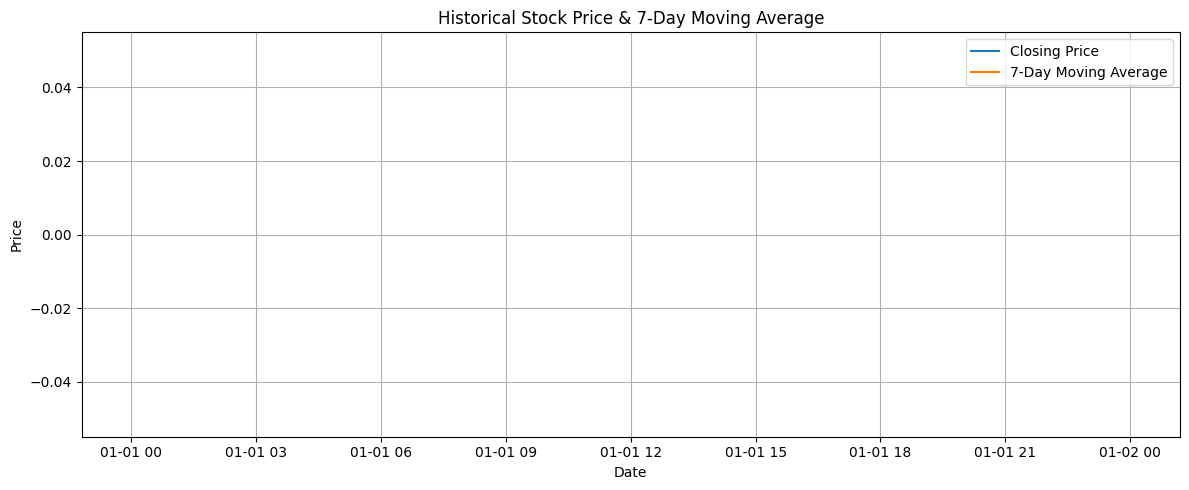

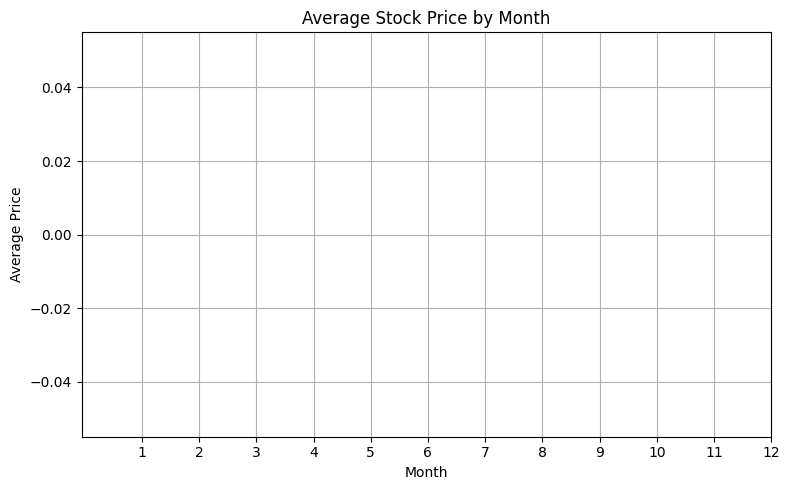

Correlation between Closing Price and Volume: nan


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Calculate 7-Day Moving Average
df['MA7'] = df['Closing_Price'].rolling(window=7).mean()

# 2. Historical Stock Price and Moving Average
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Closing_Price'], label='Closing Price')
plt.plot(df.index, df['MA7'], label='7-Day Moving Average')

plt.title('Historical Stock Price & 7-Day Moving Average')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. Average Stock Price by Month
monthly_sales = df.groupby(df.index.month)['Closing_Price'].mean()

plt.figure(figsize=(8, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker='o')

plt.title('Average Stock Price by Month')
plt.xlabel('Month')
plt.ylabel('Average Price')
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Correlation between Closing Price and Volume
corr = df['Closing_Price'].corr(df['Volume'])

print("Correlation between Closing Price and Volume:", round(corr, 2))


c:\Users\ASUS\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\holtwinters\model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


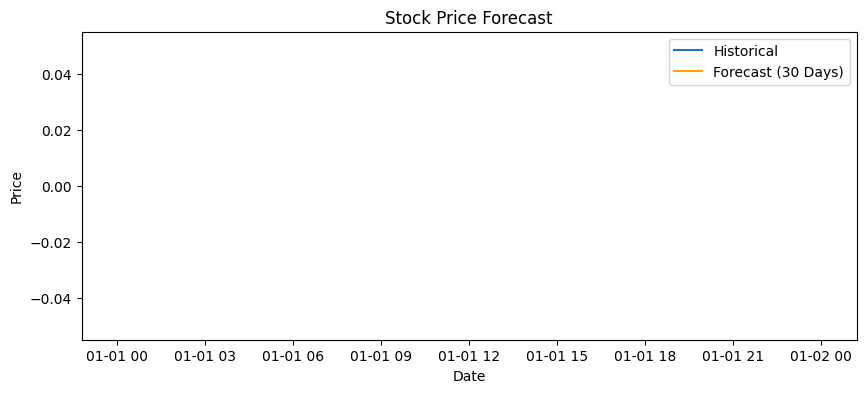

In [6]:
# 3. Forecasting with Exponential Smoothing
model = ExponentialSmoothing(df['Closing_Price'], trend='add').fit()
forecast = model.forecast(30)
future_dates = pd.date_range(df.index[-1] + pd.Timedelta(days=1), periods=30)

plt.figure(figsize=(10, 4))
plt.plot(df.index, df['Closing_Price'], label='Historical')
plt.plot(future_dates, forecast, label='Forecast (30 Days)', color='orange')
plt.title('Stock Price Forecast')
plt.xlabel('Date'); plt.ylabel('Price')
plt.legend()
plt.show()